# Model Explainability: SHAP for the XGBoost Residual Model

**Model:** `models/best_xgboost_residual_model.json` (trained in `model_xgboost_training.ipynb`)
**Data explained:** `data/processed/features-val.csv` (1994–1996). The test set stays untouched until the model is frozen.

## What SHAP explains here

The model does **not** output a risk tier. It predicts **Δ**, the change in sea surface temperature anomaly (SSTA) over the next 3 months, in °C. The forecast and tier are built afterwards:

1. The model predicts Δ from 16 features. ← **SHAP explains this step only**
2. Forecast = today's `ssta` + Δ
3. The forecast is mapped to a risk tier with the calibrated thresholds.

For each row, SHAP splits the predicted Δ into one contribution per feature:

`predicted Δ = base value + sum of SHAP values`

where the base value is the model's average prediction.

In [6]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
import lightgbm as lgb

print(f"SHAP version:    {shap.__version__}")
print(f"XGBoost version: {xgb.__version__}")

SHAP version:    0.54.1
XGBoost version: 3.4.1


## 1. Configuration

In [ ]:
DATA_DIR = "../data/processed"
VAL_PATH = os.path.join(DATA_DIR, "features-val.csv")
MODEL_PATH = "../models/best_xgboost_residual_model.json"
LGBM_MODEL_PATH = "../models/best_lightgbm_residual_model.txt"
FIGURES_DIR = "../reports/figures/shap"

# Must match FEATURES_PHYSICAL in model_xgboost_training.ipynb exactly, including order.
FEATURES_PHYSICAL = [
    "ssta", "ssta_lag1", "ssta_lag2", "ssta_lag3", "ssta_roll3", "ssta_change1", "ssta_change3",
    "basin_ssta", "nino34_ssta", "nino34_ssta_roll3", "basin_zwind_anom", "west_pac_zwind_anom",
    "air_temp_anom", "air_temp_anom_lag1", "zonal_wind_anom", "mer_wind_anom",
]

## 2. Load the validation data and the trained model

Rows are filtered the same way as in the training notebook, so we explain exactly the 1,529 rows the model was scored on.

In [9]:
val_raw = pd.read_csv(VAL_PATH)
val = val_raw.dropna(subset=["target_risk", "target_ssta", "current_risk"]).reset_index(drop=True)
X_val = val[FEATURES_PHYSICAL]

model = xgb.XGBRegressor()
model.load_model(MODEL_PATH)

# The saved model records the features it was trained on. A mismatch here would make every SHAP value wrong.
assert model.get_booster().feature_names == FEATURES_PHYSICAL, "Feature list or order differs from training"

print(f"Validation rows: {len(val):,} ({val['ym'].min()} to {val['ym'].max()})")
print(f"Missing feature values: {X_val.isna().sum().sum():,} (XGBoost and SHAP handle these natively)")

Validation rows: 1,529 (1994-01 to 1996-09)
Missing feature values: 639 (XGBoost and SHAP handle these natively)


## 3. Compute SHAP values

In [10]:
# TreeExplainer computes exact SHAP values for tree models, so this takes seconds.
explainer = shap.TreeExplainer(model)
explanation = explainer(X_val)

print(f"SHAP values shape: {explanation.values.shape} (rows x features)")
print(f"Base value (average predicted Δ): {float(np.mean(explanation.base_values)):+.4f} °C")

SHAP values shape: (1529, 16) (rows x features)
Base value (average predicted Δ): +0.0119 °C


## 4. Sanity check: SHAP values add up to the prediction

For every row, base value + sum of SHAP values must equal the model's predicted Δ. If this fails, the explanation does not describe this model.

In [11]:
pred_delta = model.predict(X_val)
reconstructed = explanation.base_values + explanation.values.sum(axis=1)
max_error = np.abs(reconstructed - pred_delta).max()

assert max_error < 1e-4, f"Additivity check failed: max error {max_error}"
print(f"Additivity check passed: max error {max_error:.2e} °C")

# The same check, row by row, for the first few rows
pd.DataFrame({
    "site_id": val["site_id"].head(),
    "ym": val["ym"].head(),
    "base value": explanation.base_values[:5],
    "sum of SHAP": explanation.values[:5].sum(axis=1),
    "base + SHAP": reconstructed[:5],
    "predicted Δ": pred_delta[:5],
}).round(4)

Additivity check passed: max error 1.79e-07 °C


,site_id,ym,base value,sum of SHAP,base + SHAP,predicted Δ
0,-2_-110,1994-01,0.0119,-0.4843,-0.4724,-0.4724
1,-2_-110,1994-02,0.0119,0.1218,0.1338,0.1338
2,-2_-110,1994-03,0.0119,0.0650,0.0769,0.0769
3,-2_-110,1994-04,0.0119,0.2108,0.2227,0.2227
4,-2_-110,1994-05,0.0119,0.1495,0.1615,0.1615


## 5. First look: average impact per feature

Mean |SHAP| is how far, on average, each feature moves the predicted Δ (in °C). This is the table behind the bar plot made in the next section.

In [12]:
mean_abs_shap = (
    pd.Series(np.abs(explanation.values).mean(axis=0), index=FEATURES_PHYSICAL, name="mean |SHAP| (°C)")
    .sort_values(ascending=False)
)
unused = mean_abs_shap[mean_abs_shap == 0].index.tolist()

print(f"Features the model uses: {len(FEATURES_PHYSICAL) - len(unused)} of {len(FEATURES_PHYSICAL)}")
print(f"Never used by any tree: {unused}")
mean_abs_shap.round(4).to_frame()

Features the model uses: 8 of 16
Never used by any tree: ['ssta_roll3', 'ssta_change1', 'basin_ssta', 'nino34_ssta', 'nino34_ssta_roll3', 'air_temp_anom_lag1', 'zonal_wind_anom', 'mer_wind_anom']


,mean |SHAP| (°C)
ssta,0.1242
ssta_lag3,0.0614
west_pac_zwind_anom,0.0412
air_temp_anom,0.0038
ssta_lag2,0.0035
basin_zwind_anom,0.0030
ssta_lag1,0.0021
ssta_change3,0.0019
ssta_roll3,0.0000
ssta_change1,0.0000


## 6. Shared plotting helpers

These functions work for any tree model explained with `shap.TreeExplainer` (XGBoost, LightGBM), so every model gets the same set of figures. Each model's figures go in their own folder: `reports/figures/shap/<model_name>/`.

- `save_summary_plots` saves the bar plot, the beeswarm and one dependence plot per top feature.
- `save_waterfall` saves the explanation of a single prediction.

In [13]:
def _save_current_figure(path):
    """Save the figure SHAP just drew, then close it so figures don't pile up in memory."""
    fig = plt.gcf()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved {path}")


def save_summary_plots(explanation, model_name, output_label, n_dependence=4):
    """Save the bar plot, the beeswarm and dependence plots for the top features.

    explanation:  a shap.Explanation for the rows being explained
    model_name:   folder name under FIGURES_DIR, e.g. "xgboost"
    output_label: what the model predicts, used in titles, e.g. "predicted 3-month change Δ (°C)"
    """
    out_dir = os.path.join(FIGURES_DIR, model_name)
    os.makedirs(out_dir, exist_ok=True)
    n_features = explanation.values.shape[1]

    shap.plots.bar(explanation, max_display=n_features, show=False)
    plt.title(f"{model_name}: average impact on {output_label}")
    _save_current_figure(os.path.join(out_dir, "bar.png"))

    shap.plots.beeswarm(explanation, max_display=n_features, show=False)
    plt.title(f"{model_name}: how each feature pushes the {output_label}")
    _save_current_figure(os.path.join(out_dir, "beeswarm.png"))

    mean_abs = np.abs(explanation.values).mean(axis=0)
    top_features = [explanation.feature_names[i] for i in np.argsort(mean_abs)[::-1][:n_dependence]]
    for feature in top_features:
        shap.plots.scatter(explanation[:, feature], show=False)
        plt.title(f"{model_name}: effect of {feature}")
        _save_current_figure(os.path.join(out_dir, f"dependence_{feature}.png"))


def save_waterfall(explanation, row, model_name, file_stem, title):
    """Save the waterfall plot explaining a single row's prediction."""
    out_dir = os.path.join(FIGURES_DIR, model_name)
    os.makedirs(out_dir, exist_ok=True)
    shap.plots.waterfall(explanation[row], max_display=10, show=False)
    plt.title(title, fontsize=10)
    _save_current_figure(os.path.join(out_dir, f"waterfall_{file_stem}.png"))

## 7. XGBoost: overall importance and direction

- **Bar plot:** average |SHAP| per feature, i.e. which features matter most overall.
- **Beeswarm:** one dot per validation row. Red means a high feature value, blue a low one; dots to the right push the predicted change warmer, dots to the left push it cooler.
- **Dependence plots:** for each of the top 4 features, the feature's value (x-axis) against its SHAP value (y-axis).

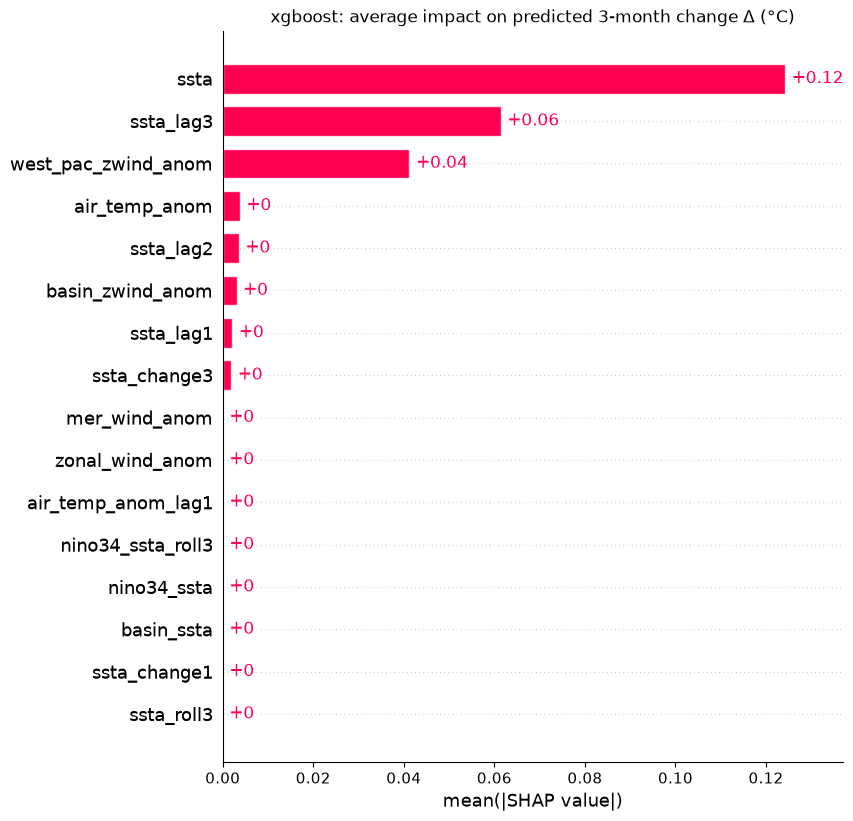

Saved ../reports/figures/shap/xgboost/bar.png


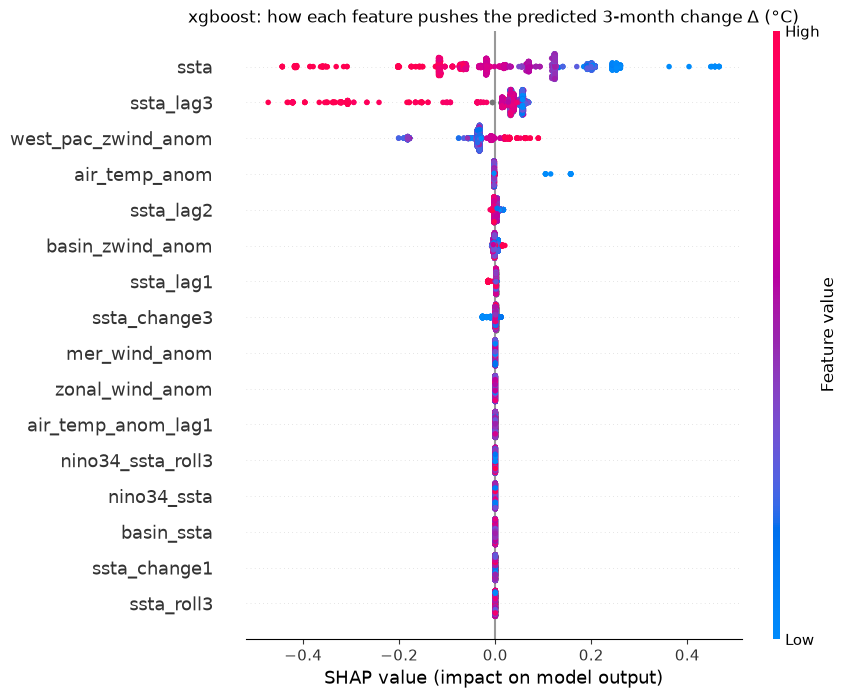

Saved ../reports/figures/shap/xgboost/beeswarm.png


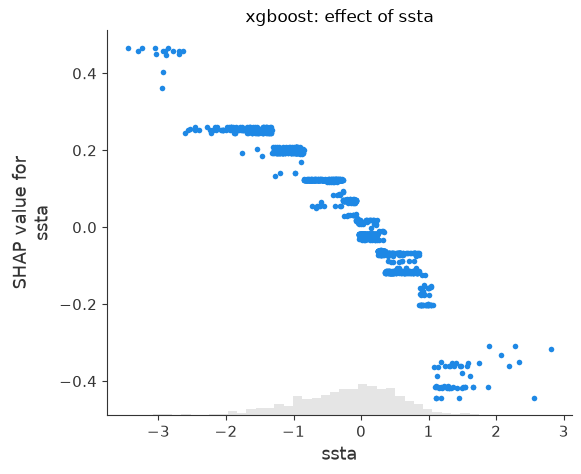

Saved ../reports/figures/shap/xgboost/dependence_ssta.png


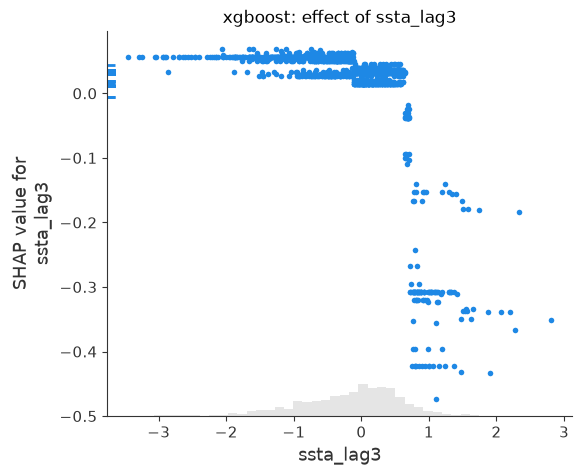

Saved ../reports/figures/shap/xgboost/dependence_ssta_lag3.png


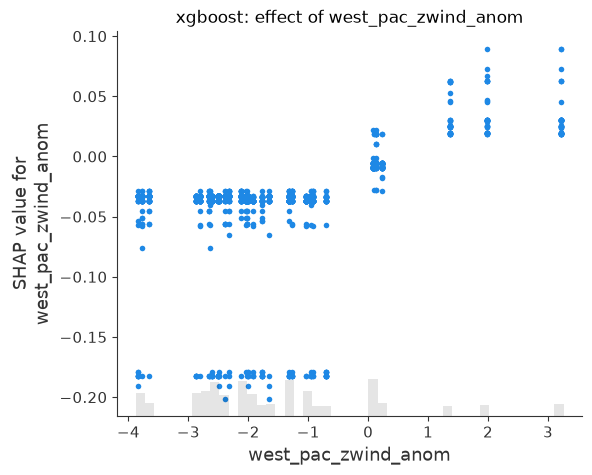

Saved ../reports/figures/shap/xgboost/dependence_west_pac_zwind_anom.png


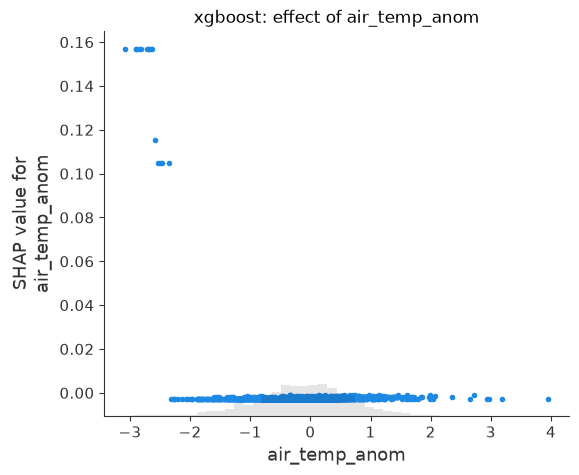

Saved ../reports/figures/shap/xgboost/dependence_air_temp_anom.png


In [14]:
save_summary_plots(explanation, model_name="xgboost", output_label="predicted 3-month change Δ (°C)")

## 8. XGBoost: explaining single forecasts

Each waterfall starts at the base value (the average predicted Δ) and adds each feature's push until it reaches this row's predicted Δ. The title shows how that Δ becomes the forecast and tier.

The three examples are verified validation rows:

| Example | Why it was chosen |
| --- | --- |
| `-2_-125`, 1995-11 | Correct Extreme Cool warning |
| `0_-170`, 1994-08 | Correct Extreme Warm warning |
| `0_-170`, 1994-07 | Missed Extreme Warm: forecast Moderate Warm, actual Extreme Warm |

Note: the `0_-110` walkthrough in `docs/MODEL_XGBOOST_TRAINING.md` (ssta −1.25, Δ −0.18, actual −1.62) does not match any validation row, so it is not reused here.

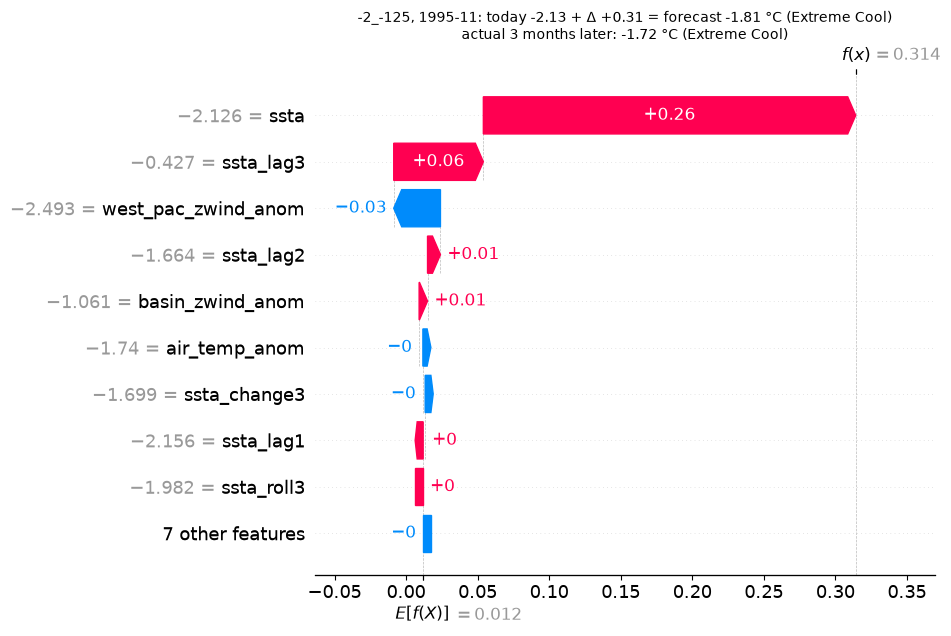

Saved ../reports/figures/shap/xgboost/waterfall_correct_extreme_cool.png


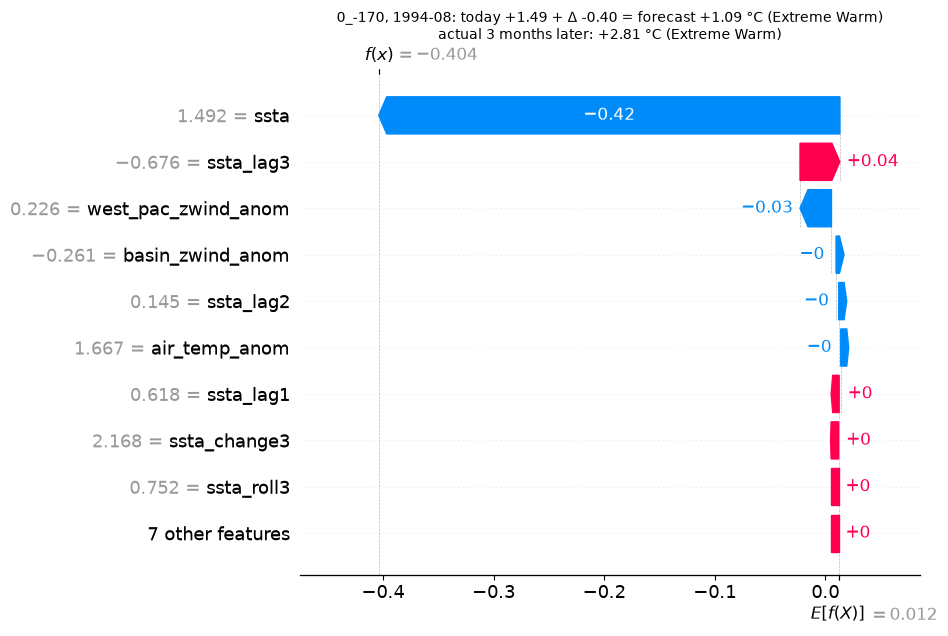

Saved ../reports/figures/shap/xgboost/waterfall_correct_extreme_warm.png


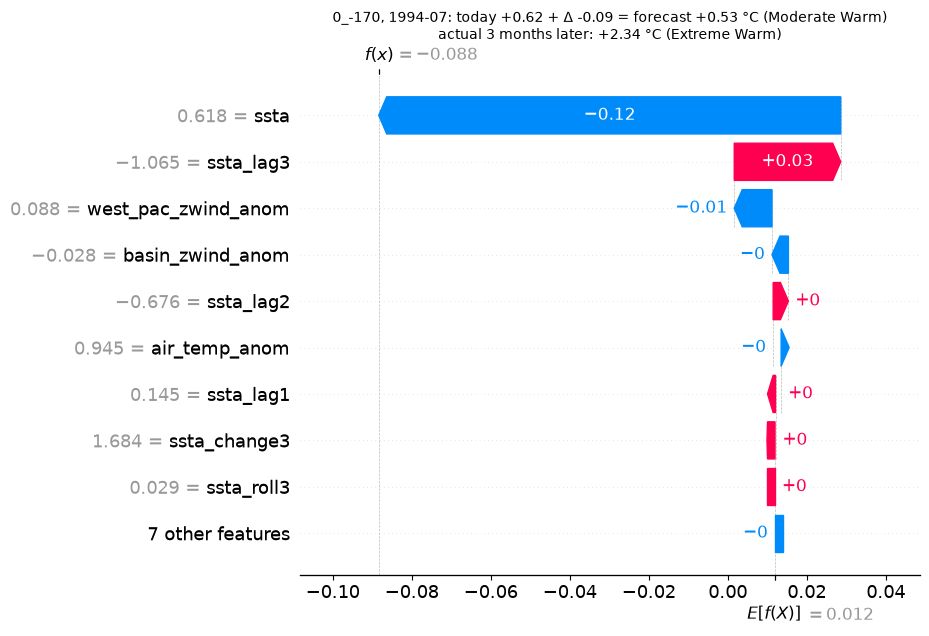

Saved ../reports/figures/shap/xgboost/waterfall_missed_extreme_warm.png


In [15]:
def classify_calibrated(anomaly):
    """Calibrated tier thresholds, copied from model_xgboost_training.ipynb."""
    if anomaly >= 1.0:  return "Extreme Warm"
    if anomaly >= 0.35: return "Moderate Warm"
    if anomaly <= -1.1: return "Extreme Cool"
    if anomaly <= -0.4: return "Moderate Cool"
    return "Neutral"


val["pred_delta"] = pred_delta
val["forecast_ssta"] = val["ssta"] + val["pred_delta"]
val["forecast_tier"] = val["forecast_ssta"].map(classify_calibrated)

EXAMPLES = [
    ("-2_-125", "1995-11", "correct_extreme_cool"),
    ("0_-170", "1994-08", "correct_extreme_warm"),
    ("0_-170", "1994-07", "missed_extreme_warm"),
]

for site_id, ym, file_stem in EXAMPLES:
    row = val.index[(val["site_id"] == site_id) & (val["ym"] == ym)][0]
    r = val.loc[row]
    title = (
        f"{site_id}, {ym}: today {r['ssta']:+.2f} + Δ {r['pred_delta']:+.2f} = forecast {r['forecast_ssta']:+.2f} °C "
        f"({r['forecast_tier']})\nactual 3 months later: {r['target_ssta']:+.2f} °C ({r['target_risk']})"
    )
    save_waterfall(explanation, row, model_name="xgboost", file_stem=file_stem, title=title)

## 9. Model checks

These checks follow "Using SHAP to improve the model" in the team's planning doc.

In [16]:
# Check 1: no location shortcuts. lat/lon were removed after the model memorized buoy coordinates.
location_features = [f for f in FEATURES_PHYSICAL if f in ("lat", "lon", "site_id")]
print(f"Location features in the model: {location_features or 'none'}")

# Check 2: direction of each used feature's effect.
# Correlation between a feature's value and its SHAP value: positive means a higher value pushes the forecast warmer.
shap_df = pd.DataFrame(explanation.values, columns=FEATURES_PHYSICAL)
used = mean_abs_shap[mean_abs_shap > 0].index
direction = pd.DataFrame({
    "mean |SHAP| (°C)": mean_abs_shap[used].round(4),
    "value vs SHAP correlation": [
        round(np.corrcoef(X_val[f][X_val[f].notna()], shap_df[f][X_val[f].notna()])[0, 1], 2) for f in used
    ],
})
direction["higher value pushes Δ"] = np.where(direction["value vs SHAP correlation"] > 0, "warmer", "cooler")
direction

Location features in the model: none


,mean |SHAP| (°C),value vs SHAP correlation,higher value pushes Δ
ssta,0.1242,-0.95,cooler
ssta_lag3,0.0614,-0.57,cooler
west_pac_zwind_anom,0.0412,0.46,warmer
air_temp_anom,0.0038,-0.31,cooler
ssta_lag2,0.0035,-0.72,cooler
basin_zwind_anom,0.0030,-0.16,cooler
ssta_lag1,0.0021,-0.45,cooler
ssta_change3,0.0019,0.42,warmer


In [17]:
# Check 3: features with no effect at all
print(f"Unused features ({len(unused)}): {unused}")

# Check 4: what limits extreme-event detection?
true_delta = val["target_ssta"] - val["ssta"]
print(f"\nPredicted Δ ranges from {val['pred_delta'].min():+.2f} to {val['pred_delta'].max():+.2f} °C "
      f"(std {val['pred_delta'].std():.2f})")
print(f"Actual Δ ranges from {true_delta.min():+.2f} to {true_delta.max():+.2f} °C (std {true_delta.std():.2f})")

extreme_warm = val[val["target_risk"] == "Extreme Warm"]
print(f"\nExtreme Warm rows: {len(extreme_warm)}; predicted Δ was negative (cooling) for "
      f"{(extreme_warm['pred_delta'] < 0).sum()} of them")
extreme_warm[["site_id", "ym", "ssta", "pred_delta", "forecast_ssta", "forecast_tier", "target_ssta"]].round(2)

Unused features (8): ['ssta_roll3', 'ssta_change1', 'basin_ssta', 'nino34_ssta', 'nino34_ssta_roll3', 'air_temp_anom_lag1', 'zonal_wind_anom', 'mer_wind_anom']

Predicted Δ ranges from -0.87 to +0.70 °C (std 0.22)
Actual Δ ranges from -5.60 to +2.95 °C (std 0.78)

Extreme Warm rows: 17; predicted Δ was negative (cooling) for 15 of them


,site_id,ym,ssta,pred_delta,forecast_ssta,forecast_tier,target_ssta
191,-2_156,1995-05,0.67,-0.12,0.56,Moderate Warm,1.62
196,-2_156,1995-10,0.49,-0.55,-0.06,Neutral,1.51
197,-2_156,1995-11,0.19,-0.54,-0.35,Neutral,1.53
203,-2_156,1996-05,0.57,-0.58,-0.01,Neutral,1.65
414,-5_156,1995-10,0.54,-0.55,-0.01,Neutral,1.54
415,-5_156,1995-11,0.32,-0.06,0.26,Neutral,1.88
416,-5_156,1995-12,0.37,-0.12,0.26,Neutral,1.65
628,0_-110,1994-07,-0.86,0.23,-0.64,Moderate Cool,1.74
660,0_-125,1994-08,0.57,-0.11,0.46,Moderate Warm,2.19
661,0_-125,1994-09,0.80,-0.19,0.62,Moderate Warm,1.90


## 10. Findings (validation set, 1994–1996)

1. **The model is mostly "today's anomaly, pulled back toward normal."** `ssta` has by far the biggest impact (0.12 °C on average, twice the next feature), and its effect runs in reverse: a warm reading today pushes the predicted change cooler, and a cold reading pushes it warmer (value vs SHAP correlation −0.95). This matches ocean physics, since anomalies tend to fade over time.
2. **Western Pacific winds are the main early-warning signal from outside the buoy itself.** Higher `west_pac_zwind_anom` (westerly wind anomalies) pushes forecasts warmer (correlation +0.46). Westerly wind bursts in the western Pacific are a known trigger for El Niño, so the model learned a physically sensible signal.
3. **Only 8 of the 16 features are used.** The model is deliberately small (40 trees, depth 2), and the Niño 3.4 and basin-wide SSTA features carry information it already gets from `ssta`. A reviewer may ask why the standard El Niño index (`nino34_ssta`) has zero impact; this is the answer.
4. **No location shortcut.** No latitude, longitude or site features are in the model, so the coordinate-memorizing problem from earlier experiments is gone.
5. **The model can't forecast fast warming, which is why it misses Extreme Warm events.** Predicted changes stay between −0.87 and +0.70 °C (std 0.22), while actual changes reach +2.95 °C (std 0.78). For 15 of the 17 Extreme Warm rows, the model predicted cooling. The pull-back-to-normal effect in finding 1 dominates exactly when an El Niño is building. In the missed example (`0_-170`, 1994-07), the buoy had already warmed 1.68 °C over the previous 3 months (`ssta_change3`), but the model gave that momentum almost no weight. Momentum features are a candidate to strengthen (see the interaction features on the XGBoost doc's roadmap).

## 11. LightGBM: load the model and compute SHAP values

**Model:** `models/best_lightgbm_residual_model.txt` (trained in `model_lightgbm_training.ipynb`)
**Data explained:** the same validation rows as the XGBoost model (1994–1996), so the two models can be compared row by row.

Like the XGBoost model, this model predicts **Δ**, the 3-month change `target_ssta − ssta`, and the forecast is built afterwards as `ssta + Δ`. It differs in one way: it was trained on all **36 features** in `features-*.csv`, not the 16 `FEATURES_PHYSICAL`. The feature list is read from the saved model, so the order always matches training.

SHAP splits each predicted Δ into one contribution per feature:

`predicted Δ = base value + sum of SHAP values`

where the base value is the model's average predicted Δ. The additivity check below confirms this holds for every row.

In [24]:
lgbm_model = lgb.Booster(model_file=LGBM_MODEL_PATH)
# If you saved it with joblib instead: lgbm_model = joblib.load(LGBM_MODEL_PATH)

LGBM_FEATURES = lgbm_model.feature_name()   # the 36 features, in training order
X_val_lgb = val[LGBM_FEATURES]
pred_delta_lgb = lgbm_model.predict(X_val_lgb)   # predicts the 3-month change Δ, like XGBoost

explainer_lgb = shap.TreeExplainer(lgbm_model)
explanation_lgb = explainer_lgb(X_val_lgb)

# Additivity check: base value + SHAP values must equal the prediction
reconstructed_lgb = explanation_lgb.base_values + explanation_lgb.values.sum(axis=1)
max_error_lgb = np.abs(reconstructed_lgb - pred_delta_lgb).max()
assert max_error_lgb < 1e-4, f"Additivity check failed: max error {max_error_lgb}"

print(f"Additivity check passed: max error {max_error_lgb:.2e} °C")
print(f"Base value (average predicted Δ): {float(np.mean(explanation_lgb.base_values)):+.4f} °C")

Additivity check passed: max error 9.99e-16 °C
Base value (average predicted Δ): +0.0112 °C


## 12. LightGBM: overall importance and direction

Same three plots as for XGBoost, saved to `reports/figures/shap/lightgbm/`. SHAP values are in °C of the predicted change Δ.

- **Bar plot:** average |SHAP| per feature, i.e. which features matter most overall.
- **Beeswarm:** one dot per validation row. Red means a high feature value, blue a low one; dots to the right push the predicted change warmer, dots to the left push it cooler.
- **Dependence plots:** for each of the top 4 features, the feature's value (x-axis) against its SHAP value (y-axis).

Because the target is a change, a feature whose high values push Δ **cooler** is a "pull back toward normal" signal, and one whose high values push Δ **warmer** is a "keeps going" signal.

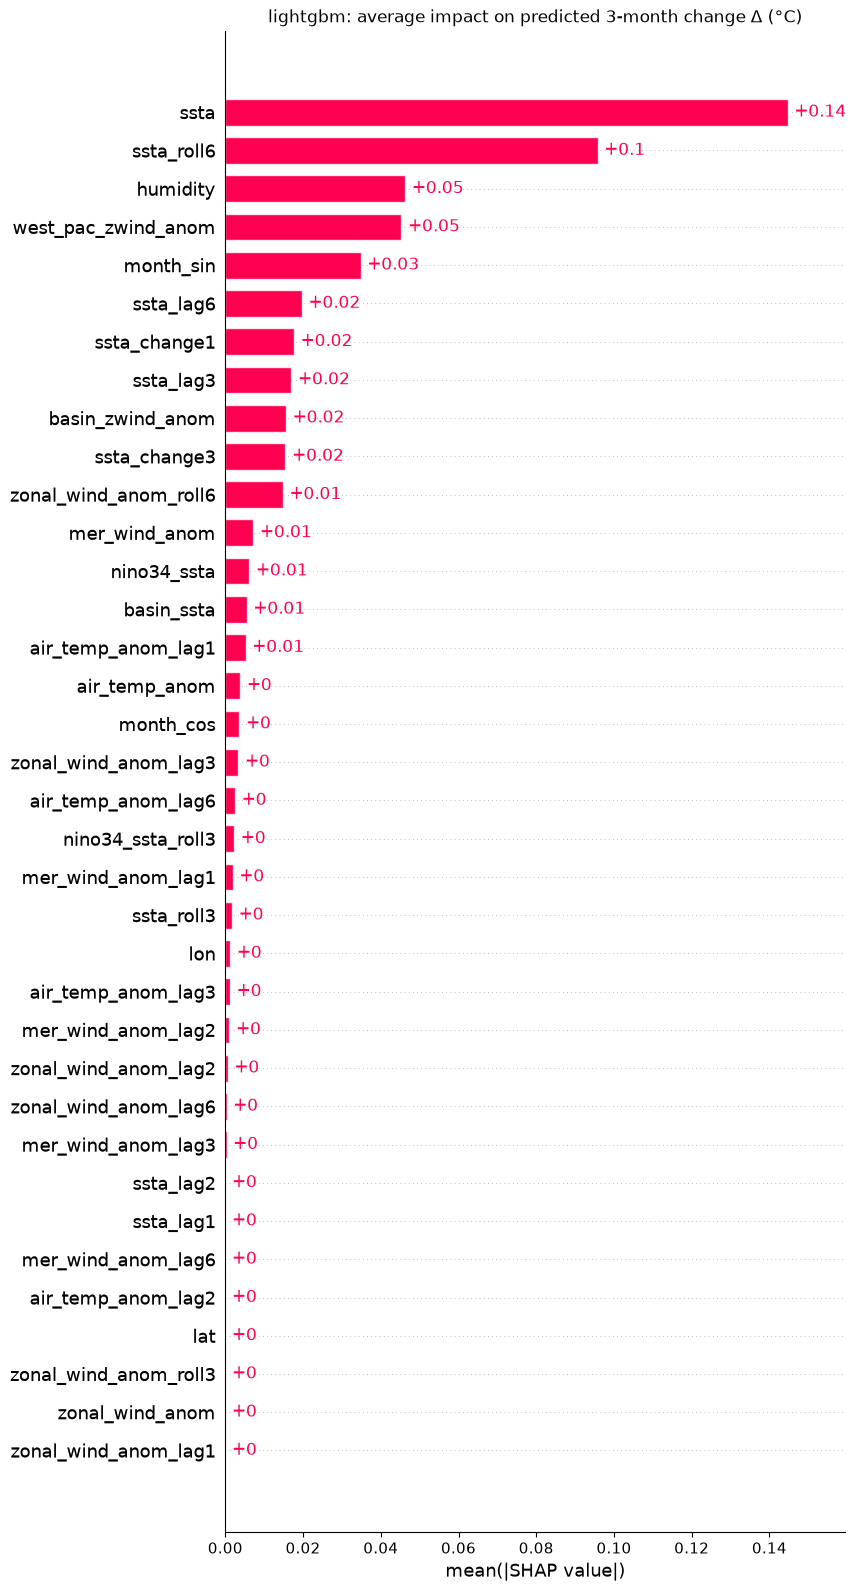

Saved ../reports/figures/shap/lightgbm/bar.png


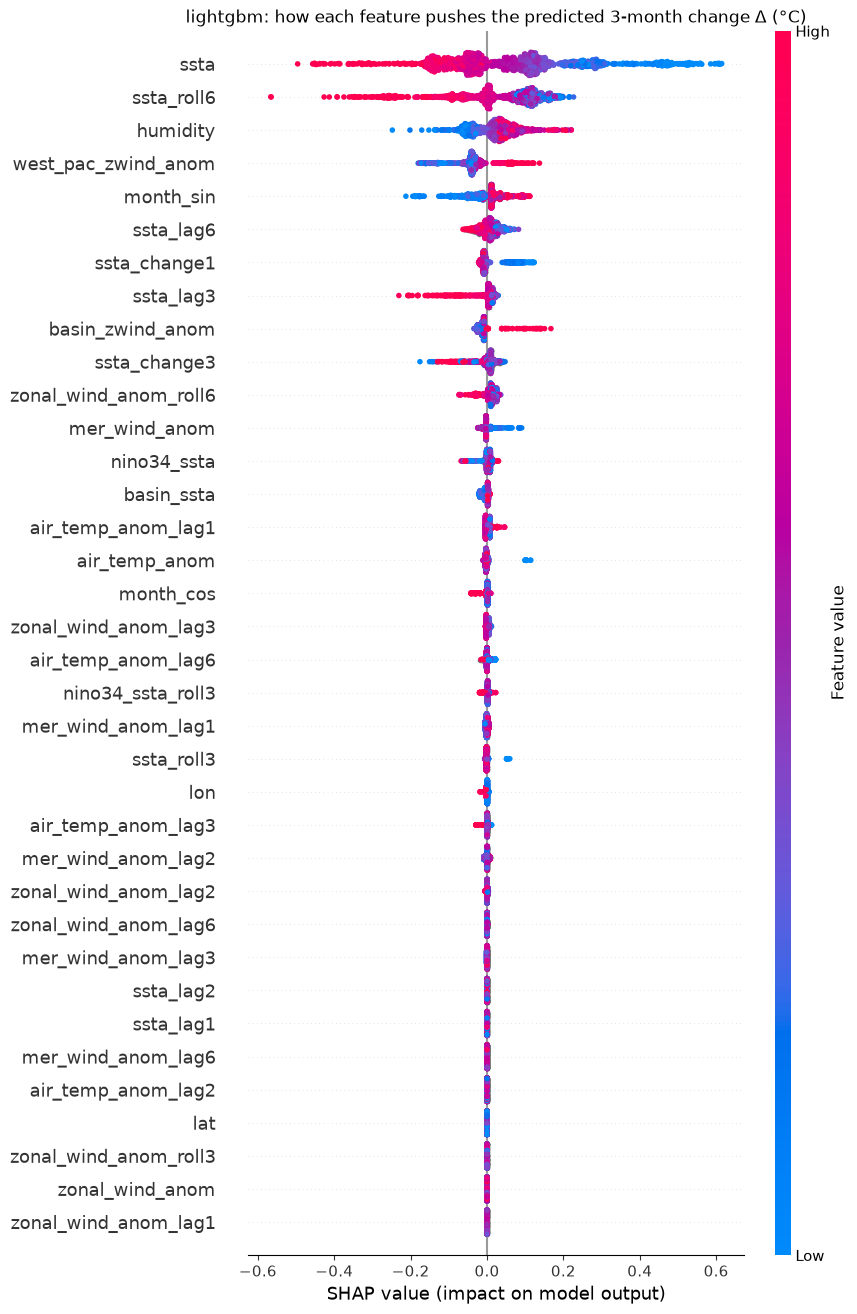

Saved ../reports/figures/shap/lightgbm/beeswarm.png


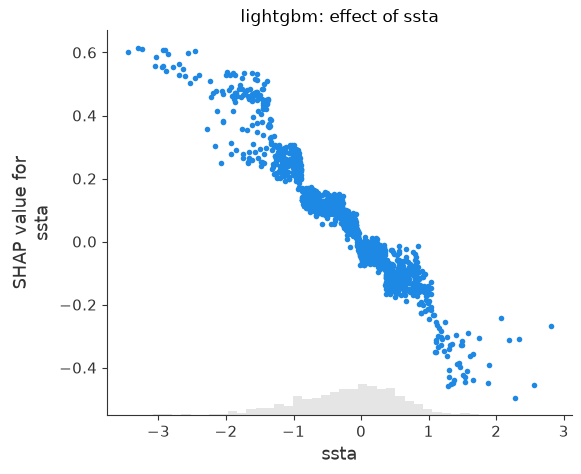

Saved ../reports/figures/shap/lightgbm/dependence_ssta.png


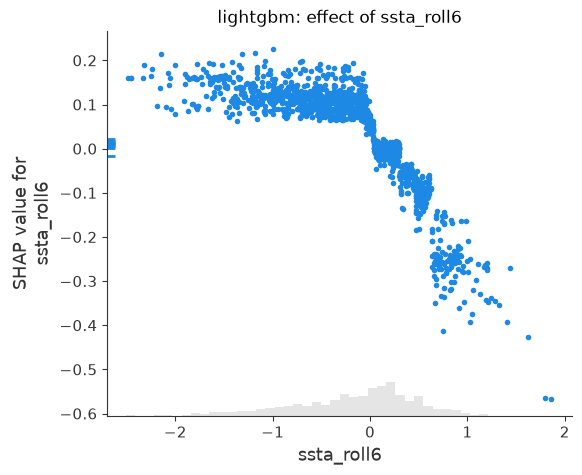

Saved ../reports/figures/shap/lightgbm/dependence_ssta_roll6.png


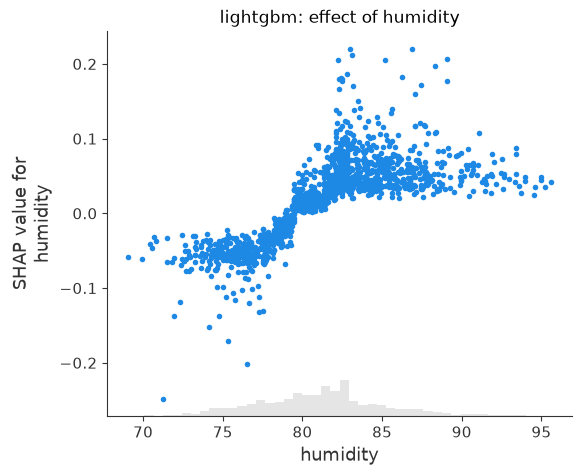

Saved ../reports/figures/shap/lightgbm/dependence_humidity.png


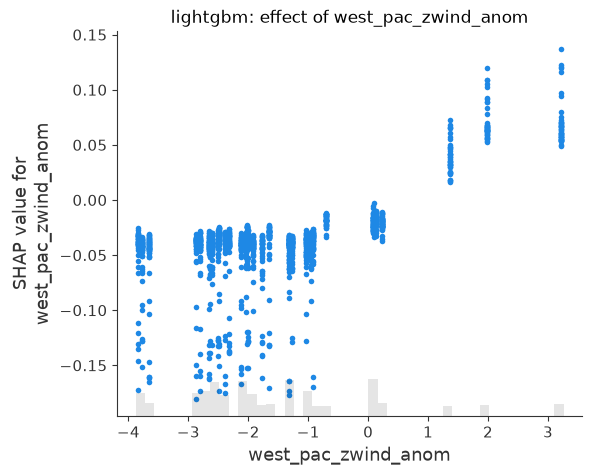

Saved ../reports/figures/shap/lightgbm/dependence_west_pac_zwind_anom.png


In [25]:
save_summary_plots(
    explanation_lgb,
    model_name="lightgbm",   # saves to reports/figures/shap/lightgbm/
    output_label="predicted 3-month change Δ (°C)",
)

## 13. LightGBM: explaining single forecasts

Each waterfall starts at the base value (the average predicted Δ) and adds each feature's push until it reaches this row's predicted Δ. The title shows how that Δ becomes the forecast and tier.

These are the same three validation rows used in Section 8, chosen for their XGBoost outcomes so the two models can be compared on identical cases:

| Example | Why it was chosen |
| --- | --- |
| `-2_-125`, 1995-11 | Correct Extreme Cool warning |
| `0_-170`, 1994-08 | Correct Extreme Warm warning |
| `0_-170`, 1994-07 | Missed Extreme Warm: forecast Moderate Warm, actual Extreme Warm |

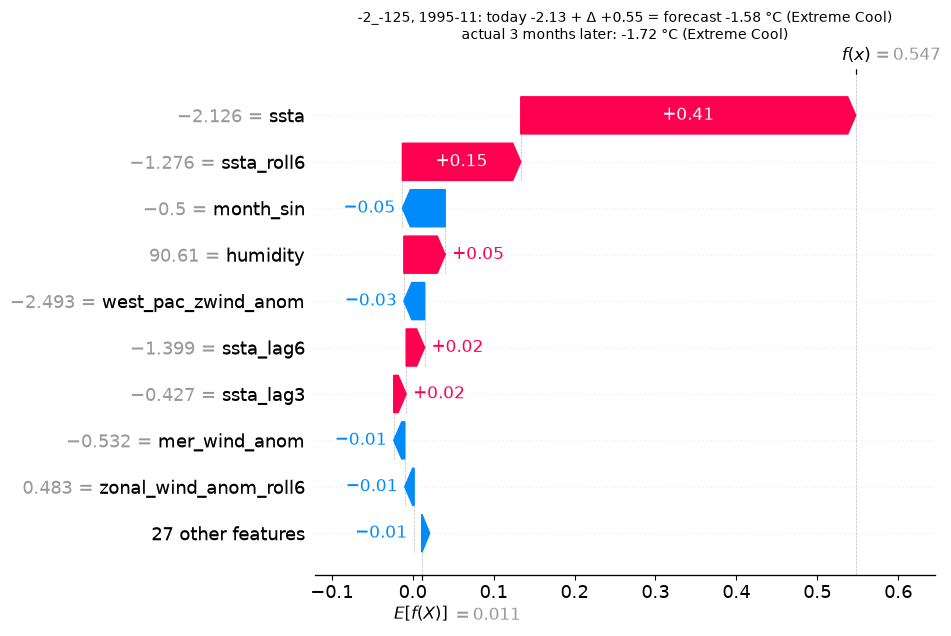

Saved ../reports/figures/shap/lightgbm/waterfall_correct_extreme_cool.png


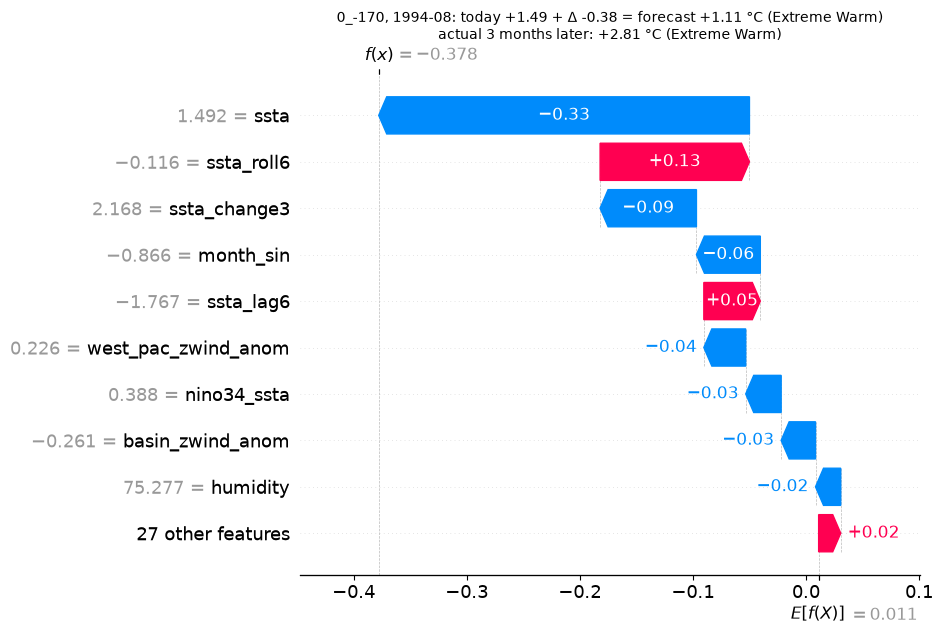

Saved ../reports/figures/shap/lightgbm/waterfall_correct_extreme_warm.png


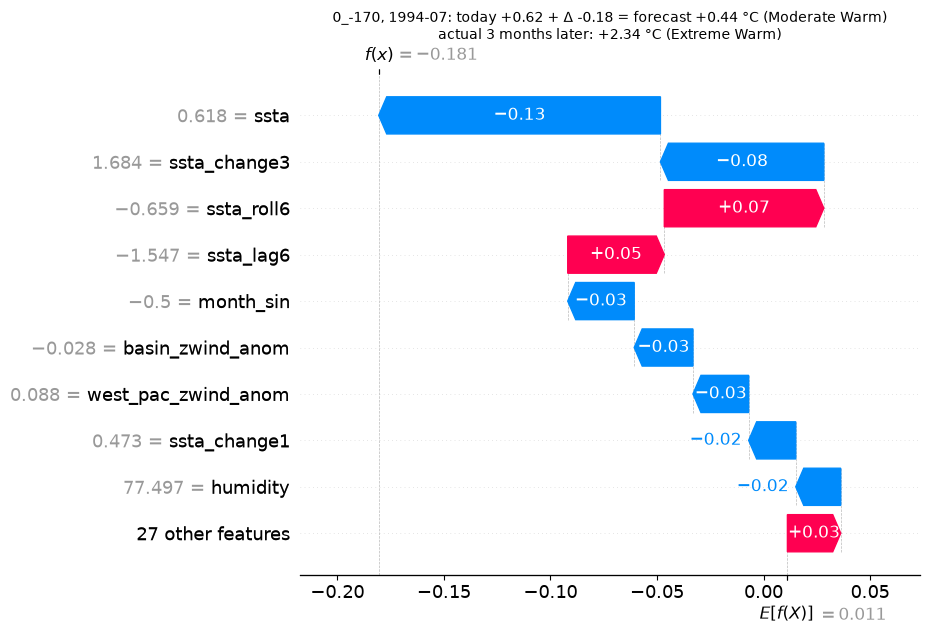

Saved ../reports/figures/shap/lightgbm/waterfall_missed_extreme_warm.png


In [26]:
val["lgbm_pred_delta"] = pred_delta_lgb
val["lgbm_forecast_ssta"] = val["ssta"] + val["lgbm_pred_delta"]
val["lgbm_forecast_tier"] = val["lgbm_forecast_ssta"].map(classify_calibrated)

for site_id, ym, file_stem in EXAMPLES:
    row = val.index[(val["site_id"] == site_id) & (val["ym"] == ym)][0]
    r = val.loc[row]
    title = (
        f"{site_id}, {ym}: today {r['ssta']:+.2f} + Δ {r['lgbm_pred_delta']:+.2f} = forecast {r['lgbm_forecast_ssta']:+.2f} °C "
        f"({r['lgbm_forecast_tier']})\n"
        f"actual 3 months later: {r['target_ssta']:+.2f} °C ({r['target_risk']})"
    )
    save_waterfall(explanation_lgb, row, model_name="lightgbm", file_stem=file_stem, title=title)

## 14. LightGBM findings (validation set, 1994–1996)

1. **Like XGBoost, the model is mostly "today's anomaly, pulled back toward normal," but it spreads the work over more features.** `ssta` has the biggest impact (0.14 °C on average, about 28% of total), followed by `ssta_roll6` (0.10 °C), `humidity` and `west_pac_zwind_anom` (0.05 °C each) and `month_sin` (0.03 °C). A warm reading today pushes the predicted change cooler: SHAP falls from about +0.6 °C at `ssta` ≈ −3 °C to about −0.45 °C at `ssta` ≈ +2.5 °C.
2. **Recent warm history also pushes toward cooling.** `ssta_roll6` is flat at +0.1 to +0.2 °C below 0, then falls steeply once the 6-month average is above 0 (about −0.25 °C near +0.7 °C, about −0.4 °C near +1.4 °C). High `ssta_lag3` and `ssta_change3` also push Δ cooler. The SSTA-history features together carry about 60% of the impact, so a fast rise over the last 3 months is read as a reason to expect a pull-back, not continued warming.
3. **Western Pacific winds are the warming signal.** Positive `west_pac_zwind_anom` pushes Δ warmer (about +0.05 to +0.14 °C) and negative values push it cooler (about −0.04 °C, some rows down to −0.17 °C). High `basin_zwind_anom` also pushes warmer. The vertical stripes in the plot suggest one wind value per month shared by all buoys, with only a few distinct values at the warm end.
4. **Humidity and season matter, but read them with care.** Humidity pushes Δ down (about −0.05 °C) below roughly 78% and up (about +0.05 °C) above roughly 83%, with a fast rise in between. Humidity is missing for 586 of 1,988 training rows (before Nov 1989) and for none in validation, so part of its effect may reflect the period, not just the physics. `month_sin` is a seasonal timing effect, not a physical driver.
5. **No location shortcut.** `lat` and `lon` have almost no impact, even though this model was allowed to use them.
6. **Single forecasts (forecast = today + Δ):**

| Example | Today | Δ | Forecast | Actual | Result |
| --- | --- | --- | --- | --- | --- |
| `-2_-125`, 1995-11 | −2.13 °C | +0.55 °C | −1.58 °C (Extreme Cool) | −1.72 °C (Extreme Cool) | Correct. A very cold buoy is pulled back toward normal (`ssta` +0.41, `ssta_roll6` +0.15), and the forecast is close. |
| `0_-170`, 1994-08 | +1.49 °C | −0.38 °C | +1.11 °C (Extreme Warm) | +2.81 °C (Extreme Warm) | Correct tier, but only because today's anomaly was already above the 1.0 °C threshold. The forecast is 1.7 °C too low. |
| `0_-170`, 1994-07 | +0.62 °C | −0.18 °C | +0.44 °C (Moderate Warm) | +2.34 °C (Extreme Warm) | Missed. |

   In both 1994 rows the actual change was strongly positive (+1.32 °C and +1.72 °C), but the model predicted cooling. `ssta` (−0.33 and −0.13 °C) and `ssta_change3` (−0.09 and −0.08 °C) both pull the forecast down. The pull-back habit that helps in the cold case works against the model when a warm event is building. Three rows can't show how often this happens, so repeat the Extreme Warm check from Section 9 for this model to count it.

## 15. XGBoost vs LightGBM: do both models rely on the same features?

This comparison feeds the website's results screen. Both models predict the same target, the 3-month change Δ, so their SHAP values are in the same units (°C of Δ) and their directions can be compared directly. The bar chart shows each feature's **share of total impact** (its mean |SHAP| divided by the sum over all features), because the two models spread their impact very differently.

The table shows each feature's share and rank in both models, plus its direction (the correlation between the feature's value and its SHAP value; positive means a higher value pushes Δ warmer). The summary lines give the overlap of the two top-5 lists and a rank correlation (1 means both models order the features the same way).

One caveat applies throughout: **the feature sets differ.** XGBoost sees 16 features and LightGBM sees 36, including `lat`, `lon`, `humidity` and month features. A feature that only LightGBM has shows 0% for XGBoost.

Top-5 features in both models: ['ssta', 'west_pac_zwind_anom']
Only XGBoost's top 5: ['air_temp_anom', 'ssta_lag2', 'ssta_lag3'] | only LightGBM's top 5: ['humidity', 'month_sin', 'ssta_roll6']
Rank agreement (Spearman): 0.26  (1 = same order, 0 = unrelated)


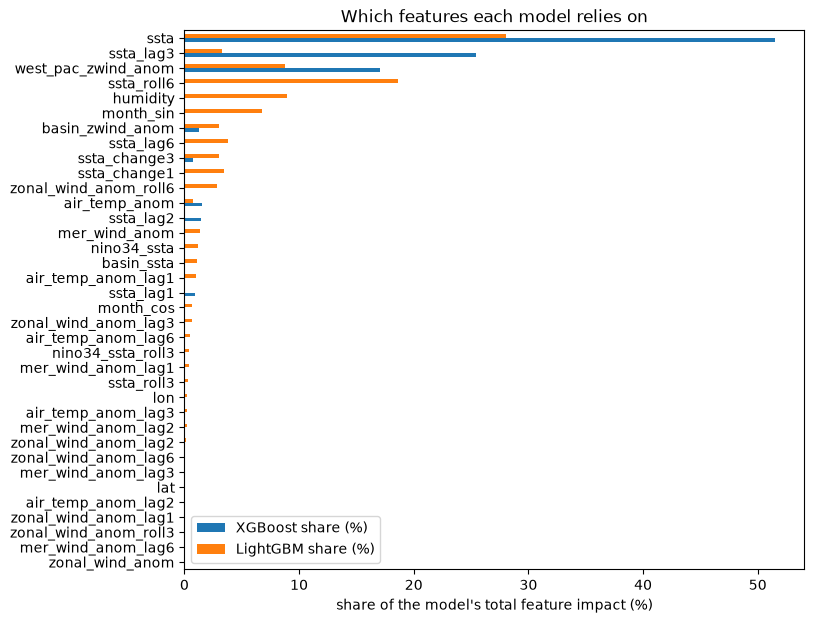

Saved ../reports/figures/shap/comparison/feature_share_comparison.png


,XGBoost share (%),LightGBM share (%),XGBoost rank,LightGBM rank,XGBoost direction,LightGBM direction
ssta,51.5,28.1,1,1,-1.0,-1.0
ssta_lag3,25.5,3.3,2,8,-0.6,-0.6
west_pac_zwind_anom,17.1,8.8,3,4,0.5,0.7
air_temp_anom,1.6,0.7,4,16,-0.3,-0.3
ssta_lag2,1.5,0.0,5,29,-0.7,NaN
basin_zwind_anom,1.3,3.0,6,9,-0.2,0.4
ssta_lag1,0.9,0.0,7,29,-0.4,NaN
ssta_change3,0.8,3.0,8,10,0.4,-0.3
air_temp_anom_lag6,0.0,0.5,9,19,NaN,-0.5
air_temp_anom_lag3,0.0,0.2,9,24,NaN,-0.5


In [23]:
def value_vs_shap(X, explanation):
    """Correlation of a feature's value with its SHAP value. Positive: higher value pushes the prediction up."""
    out = {}
    for i, f in enumerate(X.columns):
        ok = X[f].notna().to_numpy()
        s = explanation.values[ok, i]
        out[f] = np.corrcoef(X[f].to_numpy()[ok], s)[0, 1] if s.std() > 0 else np.nan
    return pd.Series(out)

mean_abs_lgbm = pd.Series(np.abs(explanation_lgb.values).mean(axis=0), index=LGBM_FEATURES)
all_features = list(dict.fromkeys(FEATURES_PHYSICAL + LGBM_FEATURES))

# Compare SHARE of total impact, because the two models predict different things
compare = pd.DataFrame({
    "XGBoost share (%)": 100 * mean_abs_shap / mean_abs_shap.sum(),
    "LightGBM share (%)": 100 * mean_abs_lgbm / mean_abs_lgbm.sum(),
}).reindex(all_features).fillna(0)

compare["XGBoost rank"] = compare["XGBoost share (%)"].rank(ascending=False, method="min").astype(int)
compare["LightGBM rank"] = compare["LightGBM share (%)"].rank(ascending=False, method="min").astype(int)
compare["XGBoost direction"] = value_vs_shap(X_val, explanation).round(2)
compare["LightGBM direction"] = value_vs_shap(X_val_lgb, explanation_lgb).round(2)
compare = compare.sort_values("XGBoost share (%)", ascending=False)

top_x = set(compare.nlargest(5, "XGBoost share (%)").index)
top_l = set(compare.nlargest(5, "LightGBM share (%)").index)
rank_corr = compare["XGBoost share (%)"].rank().corr(compare["LightGBM share (%)"].rank())

print(f"Top-5 features in both models: {sorted(top_x & top_l)}")
print(f"Only XGBoost's top 5: {sorted(top_x - top_l)} | only LightGBM's top 5: {sorted(top_l - top_x)}")
print(f"Rank agreement (Spearman): {rank_corr:.2f}  (1 = same order, 0 = unrelated)")

# Figure for the website's results screen
plot_df = compare[["XGBoost share (%)", "LightGBM share (%)"]]
plot_df = plot_df.loc[plot_df.mean(axis=1).sort_values().index]
plot_df.plot.barh(figsize=(8, 7))
plt.xlabel("share of the model's total feature impact (%)")
plt.title("Which features each model relies on")
out_dir = os.path.join(FIGURES_DIR, "comparison")
os.makedirs(out_dir, exist_ok=True)
_save_current_figure(os.path.join(out_dir, "feature_share_comparison.png"))

compare.round(1)

## 16. XGBoost vs LightGBM findings (validation set, 1994–1996)

| Feature | XGBoost share | LightGBM share |
| --- | --- | --- |
| `ssta` | ≈ 52% | ≈ 28% |
| `ssta_lag3` | ≈ 25% | ≈ 3% |
| `west_pac_zwind_anom` | ≈ 17% | ≈ 9% |
| `ssta_roll6` | not in its 16 features | ≈ 18% |
| `humidity` | not in its 16 features | ≈ 9% |
| `month_sin` | not in its 16 features | ≈ 7% |

1. **Both models are mean-reversion models first.** Each ranks `ssta` first. In both, a warm `ssta` pushes the predicted change cooler (XGBoost correlation −0.95) and positive `west_pac_zwind_anom` pushes it warmer (XGBoost correlation +0.46). Only 2 of the 5 top features overlap (`ssta` and `west_pac_zwind_anom`).
2. **XGBoost is concentrated and LightGBM is spread out.** `ssta`, `ssta_lag3` and `west_pac_zwind_anom` carry about 94% of XGBoost's impact, and only 8 of its 16 features are used. The same three carry about 40% of LightGBM's impact, and 15 of its 36 features show at least +0.01 °C.
3. **LightGBM adjusts forecasts more strongly.** In raw terms `ssta` averages 0.12 °C for XGBoost and 0.14 °C for LightGBM, even though its share is smaller (about 52% vs 28%). That implies LightGBM's total impact is roughly twice as large. Bigger adjustments do not mean better forecasts; compare the validation scores for that.
4. **They pick up the recent trend through different features.** XGBoost leans on `ssta_lag3` (SSTA 3 months ago) and LightGBM on `ssta_roll6` (the 6-month average). This comparison can't show whether they carry the same information.
5. **Both share the same weakness.** XGBoost predicted cooling for 15 of 17 Extreme Warm rows. The two 1994 LightGBM examples show the same pattern, and the one correct tier clears the 1.0 °C threshold only because today's anomaly was already warm.

**For the results screen:** both models mainly expect today's SSTA to fade toward normal and treat western Pacific winds as the warming signal. They differ in how much weight goes to older SSTA history and to extra features such as humidity and season, and both struggle when a warm event is building.